<a href="https://colab.research.google.com/github/findsamirks-commits/Multi-Agent-Supply-Chain-Orchestration/blob/main/notebooks/FNV-Markdown-Classifier-ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Fruits & Vegetables: Dynamic Markdown Classifier (Machine Learning Track)

In this step, we generate a structured dataset representing daily perishable inventory metrics.
We manually engineer a critical retail feature—**Days of Cover** (Inventory / Avg Daily Sales)—and establish our target business logic: if Days of Cover exceeds Days to Expiry, the SKU requires an immediate markdown to prevent shrink.*italicized text*

In [ ]:
import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Set random seed for reproducibility
np.random.seed(42)

# 1. Generate Synthetic F&V Inventory Data
n_samples = 1000

data = {
    'SKU_ID': [f'FNV-{i:04d}' for i in range(1, n_samples + 1)],
    'Category': np.random.choice(['Leafy Greens', 'Root Veg', 'Exotic Fruits', 'Daily Veg'], n_samples),
    'Inventory_Units': np.random.randint(20, 500, n_samples),
    'Avg_Daily_Sales': np.random.randint(5, 100, n_samples),
    'Days_to_Expiry': np.random.randint(1, 10, n_samples),
    'Historical_Shrink_Pct': np.random.uniform(0.02, 0.15, n_samples)
}

df = pd.DataFrame(data)

# Feature Engineering: Calculate Days of Cover (Inventory / Avg Daily Sales)
df['Days_of_Cover'] = df['Inventory_Units'] / df['Avg_Daily_Sales']

# 2. Define the Target Variable (Business Logic for Markdown)
# If we have more days of cover than days to expiry, we are at risk of shrink and need a markdown (1).
df['Needs_Markdown'] = np.where(df['Days_of_Cover'] > df['Days_to_Expiry'], 1, 0)

print(f"Dataset generated with {df.shape[0]} rows and {df.shape[1]} columns.")
print(f"Total SKUs requiring immediate markdown: {df['Needs_Markdown'].sum()}")
display(df.head())

Dataset generated with 1000 rows and 8 columns.
Total SKUs requiring immediate markdown: 539


,SKU_ID,Category,Inventory_Units,Avg_Daily_Sales,Days_to_Expiry,Historical_Shrink_Pct,Days_of_Cover,Needs_Markdown
0,FNV-0001,Exotic Fruits,466,49,9,0.140800,9.510204,1
1,FNV-0002,Daily Veg,164,7,4,0.072663,23.428571,1
2,FNV-0003,Leafy Greens,220,41,4,0.137794,5.365854,1
3,FNV-0004,Exotic Fruits,436,47,2,0.061794,9.276596,1
4,FNV-0005,Exotic Fruits,231,44,6,0.081937,5.250000,0


## Data Preprocessing and XGBoost Training

Machine Learning algorithms cannot natively process text categories. We use **One-Hot Encoding** (`pd.get_dummies`) to convert string variables like "Leafy Greens" into numerical binary columns.

After splitting the data into training and testing sets, we train an XGBoost classifier. The resulting Feature Importance chart reveals exactly which engineered variables the model prioritized, showcasing the highly transparent and structured nature of traditional ML.

Training features shape: (800, 8)
Testing features shape: (200, 8)

🚀 Training XGBoost Model...

📊 Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      0.99        91
           1       1.00      0.99      1.00       109

    accuracy                           0.99       200
   macro avg       0.99      1.00      0.99       200
weighted avg       1.00      0.99      1.00       200



<Figure size 1000x600 with 0 Axes>

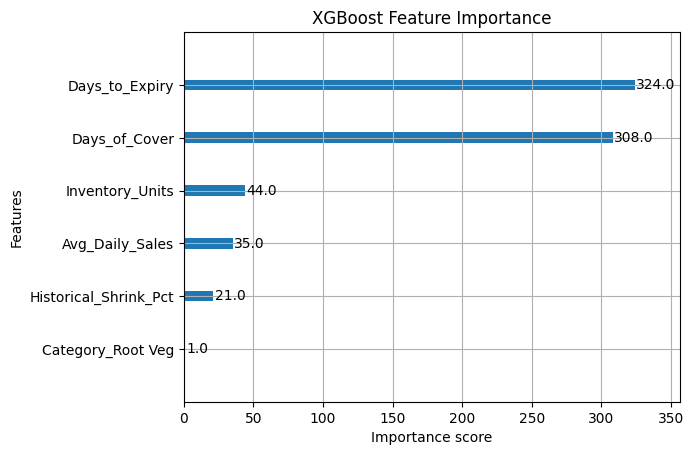

In [ ]:
# 3. Data Preprocessing
# Drop the SKU_ID as it has no predictive value
X = df[['Category', 'Inventory_Units', 'Avg_Daily_Sales', 'Days_to_Expiry', 'Historical_Shrink_Pct', 'Days_of_Cover']]
y = df['Needs_Markdown']

# Convert the categorical 'Category' column into numerical dummy variables
X_encoded = pd.get_dummies(X, columns=['Category'], drop_first=True)

# Split data into training (80%) and testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.2, random_state=42)

print(f"Training features shape: {X_train.shape}")
print(f"Testing features shape: {X_test.shape}")

# 4. Initialize and Train the XGBoost Classifier
print("\n🚀 Training XGBoost Model...")
xgb_model = xgb.XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=4,
    random_state=42,
    eval_metric='logloss'
)

xgb_model.fit(X_train, y_train)

# 5. Evaluate the Model
y_pred = xgb_model.predict(X_test)
print("\n📊 Classification Report:")
print(classification_report(y_test, y_pred))

# Plot Feature Importance
plt.figure(figsize=(10, 6))
xgb.plot_importance(xgb_model, importance_type='weight', max_num_features=10, title='XGBoost Feature Importance')
plt.show()